---
title: "DeCoursey (1974): an explicit enhancement factor for the Danckwerts surface-renewal model, tested against the exact model"
description: "DeCoursey's explicit enhancement factor, Eq. (21), was derived for Danckwerts surface renewal but could only be compared with Higbie numbers; this page solves the exact surface-renewal model over the paper's own grid and tests its prediction that Eq. (21) is within about 12 per cent."
categories: [sec:F, struct:S4, tier:T1, data:tier6, phase:gas-liquid]
date: 2026-11-27
---

# DeCoursey (1974): an explicit enhancement factor for the Danckwerts model

**Catalog ID:** `F3.3` · **Structures:** `S4` (1-D transient PDE) · **Tier:** T1

A gas that dissolves into a liquid and reacts there with a dissolved reactant B is
absorbed faster than without reaction, by the enhancement factor $E$. For a
second-order reaction no closed form exists. DeCoursey (1974) derived one for
Danckwerts' surface-renewal model by replacing B at the interface by its time mean,
Eq. (21), an explicit formula. He could test it quantitatively only against numerical results for a
different model, Higbie's penetration model, because "No numerical solution to the
partial differential equations and boundary conditions of this paper for the
Danckwerts model appears to be available." (p. 1870). From the closeness of the two
models he predicted that Eq. (21) "should be within about 12 per cent of the exact
results for the Danckwerts model at all practical values of the parameters" (p. 1870).
This page solves the exact Danckwerts model (the coupled transient equations for A and
B, averaged over the exponential age distribution) over the paper's own grid of
parameters and tests that prediction there, recomputes the paper's Tables 1 and 2 with
the exact Higbie average of the same solution, and locates where the error of Eq. (21)
comes from.

In [1]:
# Bootstrap: the pymrm this page was checked with, and the gallery files it was
# published with. Works in a checkout, in CI and on a fresh Colab VM.
GALLERY_REF = "gallery-2026.11.28.6"  # replaced by the release tag at publication
PYMRM = ">=3.4.1,<4"  # equals meta.yaml pymrm_min_version, up to the next major
PAGE = "F3.3-decoursey-danckwerts-enhancement"  # equals the page directory

import os, sys, urllib.request
from pathlib import Path
_shared = next((p / "shared" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "shared" / "gallery_bootstrap.py").is_file()), None)
if _shared is None:
    _shared = (Path(os.environ.get("XDG_CACHE_HOME") or Path.home() / ".cache")
               / "pymrm-gallery" / GALLERY_REF)
    _shared.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/computational-chemical-engineering/"
        f"pymrm-gallery/{GALLERY_REF}/shared/gallery_bootstrap.py",
        _shared / "gallery_bootstrap.py")
sys.path.insert(0, str(_shared))
sys.modules.pop("gallery_bootstrap", None)
from gallery_bootstrap import setup
setup(PAGE, PYMRM, GALLERY_REF);  # the semicolon stops the cell echoing the path

In [2]:
# Imports. pymrm contributes the exact surface-renewal solve (operators, NumJac, newton)
# and the checks (find_roots, observed_orders); DeCoursey's relations are closed forms.
import contextlib
import io
import math
import re
import time
from dataclasses import dataclass, field, replace

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from pymrm.checks import observed_orders
from gallery_utils import Claims, assert_check_values, cite_data, load_claims, load_data, load_meta
from model import (RenewalMarch, de21_dlnM, e20_residual, e21, e22_vkh, e23_hikita_asai,
                   e_danckwerts_pfo, e_higbie_pfo, ea_from_q, extremum_log, q_from_ea, unique_root)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
claims = Claims(PAGE.split("-")[0])
T_START = time.time()


def fill(text, **v):
    """Fill ``<<name:fmt>>`` in ``text`` from ``v``."""
    def sub(m):
        name, _, fmt = m.group(1).partition(":")
        return format(v[name], fmt)
    return re.sub(r"<<([^<>]+)>>", sub, text)


def say(text, **v):
    """Prose whose numbers are written by code, so they cannot drift."""
    display(Markdown(fill(text, **v)))

## Background

In the surface-renewal picture, liquid elements reach the gas-liquid interface, absorb
gas by unsteady diffusion for a while, and are replaced by fresh liquid. Higbie gives
every element the same exposure time; Danckwerts replaces elements at random, so that
their ages are distributed exponentially with the fractional renewal rate $s$. With a
second-order reaction $A + zB \to$ products in the liquid, the absorption rate depends
on how much B is left near the interface, which itself changes with the age of the
element. The enhancement factor then needs the solution of two coupled nonlinear
diffusion-reaction equations, which, DeCoursey writes, did not appear to be available for the Danckwerts model;
Brian, Hurley and Hasseltine (1961) had it for the Higbie model, as correction charts.

DeCoursey's step was to replace the interfacial concentration of B by its time mean,
which he obtained from a linear combination of the two equations, and to keep it
constant in time: "the approximation comes chiefly from treating $B_i/B_0$ as though it
were constant with time" (p. 1869). The result, Eq. (21), is explicit in $E$, unlike
the film-model relation of Van Krevelen and Hoftijzer (`F3.2`) and the Higbie relation
of Hikita and Asai, Eq. (23). The paper then compares Eq. (21) with Brian et al.'s
Higbie numbers (Tables 1 and 2) and argues from the closeness of the Higbie and
Danckwerts models to the 12 per cent prediction above.

`F3.1` compares Eq. (21) with the exact **film** model and finds its worst error there
at $E_i = 100$. This page compares it with the model it was derived for. Not covered:
reversible reactions, $A_0 \ne 0$ and other reaction orders (the extension the paper
sketches on p. 1871), and any experiment: the paper's data source is numerical, so the
data tier is 6 (nothing measured).

## The published model

DeCoursey's model (p. 1868), with $A_0 = 0$ from p. 1869 on, is the penetration
problem for each surface element,

$$D_A \frac{\partial^2 A}{\partial x^2} - \frac{\partial A}{\partial t} - k_2 A B = 0,\qquad
  D_B \frac{\partial^2 B}{\partial x^2} - \frac{\partial B}{\partial t} - z k_2 A B = 0, \tag{2, 3}$$

with $A = 0$, $B = B_0$ at $t = 0$ and at $x \to \infty$; $A = A_i$ and
$\partial B/\partial x = 0$ (B non-volatile) at $x = 0$ (Eq. 4). The Danckwerts
average of a quantity is $\bar X = s\int_0^\infty X e^{-st}\,dt$ and
$k_L^* = \sqrt{D_A s}$. The groups are $M = D_A k_2 B_0/(k_L^*)^2$ ($= k_2 B_0/s$ for
Danckwerts), the instantaneous asymptote $E_a$, and $D_B/D_A$.

Subtracting $z$ times (2) from (3) leaves a linear equation for $B - zA$ when
$D_B = D_A$; its Danckwerts average gives the bridging relation (13) and, with
$B_0/(zA_i) = E_a - 1$ (Eq. 14, "exact only for equal diffusivities", p. 1869), the
mean interfacial B

$$\frac{\bar B_i}{B_0} = \frac{E_a - E}{E_a - 1}. \tag{15}$$

Freezing $B$ at $\bar B_i$ in (2) makes the problem linear, with
$E = \sqrt{1 + M \bar B_i/B_0}$ (Eq. 19), hence

$$E = \sqrt{1 + M\frac{E_a - E}{E_a - 1}}, \tag{20}$$

$$E = -\frac{M}{2(E_a - 1)} + \sqrt{\frac{M^2}{4(E_a - 1)^2} + \frac{E_a M}{E_a - 1} + 1}. \tag{21}$$

For comparison the paper prints the film relation of Van Krevelen and Hoftijzer,
$E = \sqrt{Mf}/\tanh\sqrt{Mf}$ with $f = (E_a - E)/(E_a - 1)$ (Eq. 22), and Hikita and
Asai's Higbie relation (Eq. 23),
$E = (\sqrt{Mf} + \tfrac{\pi}{8}/\sqrt{Mf})\,\mathrm{erf}\sqrt{4Mf/\pi} + \tfrac12 e^{-4Mf/\pi}$.

**Misprints and readings.** (M1) Eq. (23) prints erfc where erf is meant: with erfc
the relation tends to infinity as $M \to 0$ instead of to 1; with erf, and $f = 1$, it
is exactly the Higbie average of the pseudo-first-order flux (checked below). (M2)
Eq. (14) holds only at $D_B = D_A$; Table 2 is parameterised by $E_a$, so at unequal
diffusivities the page takes $q = B_0/(zA_i)$ from the exact instantaneous asymptote of
the penetration problem, $E_a = 1/\mathrm{erf}\,\lambda$ with
$e^{-\lambda^2}\mathrm{erfc}(\lambda/\sqrt r) = \sqrt r\, q\, e^{-\lambda^2/r}\mathrm{erf}\,\lambda$,
$r = D_B/D_A$ (it gives $q = E_a - 1$ at $r = 1$). (M3) Table 2 does not print the $M$
values its ranges were read at ("chosen to cover a wide range on the correction charts
of Brian et al.", p. 1870); the page uses Table 1's printed span. (M4) One symbol $M$
serves both models, each with its own $k_L^*$: for Higbie $k_L^* = 2\sqrt{D_A/(\pi t_e)}$,
so $k_2 B_0 t_e = 4M/\pi$. (M5) The corrections of Tables 1 and 2 are integers read by
DeCoursey from Brian et al.'s charts, which they "claim only ... should be within 3 per
cent of the true Higbie-model solutions" (p. 1870).

**The exact model the page solves** (not in the paper). With
$\theta = k_2 B_0 t$, $\zeta = x\sqrt{k_2 B_0/D_A}$, $a = A/A_i$, $b = B/B_0$,
$q = B_0/(zA_i)$, $r = D_B/D_A$:

$$a_\theta = a_{\zeta\zeta} - ab,\qquad b_\theta = r\, b_{\zeta\zeta} - ab/q,$$

and with the flux $F(\theta) = -a_\zeta(0, \theta)$,

$$E_D(M) = M^{-1/2}\int_0^\infty F e^{-\theta/M}\,d\theta,\qquad
  E_H(M) = \frac{\sqrt\pi}{2\sqrt{\theta_e}}\int_0^{\theta_e} F\,d\theta,\ \ \theta_e = 4M/\pi.$$

| symbol | meaning | code |
|---|---|---|
| $M$ | $D_A k_2 B_0/(k_L^*)^2$ | `M` |
| $E_a$ | instantaneous asymptote | `Ea` |
| $r$ | $D_B/D_A$ | `r` |
| $q$ | $B_0/(zA_i)$ | `q`, `q_from_ea(Ea, r)` |
| $E$ (21), (22), (23) | DeCoursey, Van Krevelen-Hoftijzer, Hikita-Asai | `e21`, `e22_vkh`, `e23_hikita_asai` |
| $E_D$, $E_H$ | exact Danckwerts and Higbie averages | `History.danckwerts`, `History.higbie` |
| $\bar b_i$ | Danckwerts mean of $b(0, \theta)$ | `History.mean_b0` |

## Parameters and assumptions

The paper's grid is Table 2: $E_a$ = 3, 6, 11, 21 and $D_B/D_A$ = 0.02, 1, 10 (12
cases), with $M$ free. The page scans $M$ over $10^{-2}$ to $10^5$ for every case, and
adds $E_a = 100$, $D_B/D_A = 1$ over $10^{-2}$ to $10^7$, the like-for-like comparison
with `F3.1`'s film result. Assumptions are the paper's: $A_0 = 0$, irreversible
reaction, B non-volatile, constant diffusivities, liquid bulk at $B_0$.

The test condition of the check values is $E_a = 6$, $D_B/D_A = 1$, $M = 24$ (the
largest correction of Table 1).

In [3]:
PN = load_data("decoursey-1974-printed-numbers.csv", page=PAGE, dtype=str, keep_default_na=False)
print(cite_data(load_meta("decoursey-1974-printed-numbers.csv", page=PAGE)))


def printed(pn, item):
    """A printed entry, as the string printed."""
    return pn.loc[pn["item"] == item, "printed"].iloc[0]


def num(pn, item):
    """A printed number as a float."""
    return float(printed(pn, item))


EA_GRID = (3.0, 6.0, 11.0, 21.0)                  # Table 2, E_a (p. 1870)
R_GRID = ("0.02", "1", "10")                      # Table 2, D_B/D_A, as printed
CASES = [(ea, rs) for ea in EA_GRID for rs in R_GRID]
EA_BIG = 100.0                                    # F3.1's largest E_i, at D_B/D_A = 1
TEST = (6.0, "1", 24.0)                           # E_a, D_B/D_A, M of the check values
M_WIN = (1e-2, 1e5)                               # the M window of every Table 2 case
M_WIN_BIG = (1e-2, 1e7)                           # the M window at E_a = 100
LEVELS = ((100, 0.08), (200, 0.04), (400, 0.02))  # (cells in eta, step in ln theta), ratio 2
T1_M = [num(PN, f"t1_M_{i}") for i in range(1, 8)]
T1_P = [num(PN, f"t1_corr_{i}") for i in range(1, 8)]
say("Printed: Table 1 at $E_a$ = <<a>>, $D_B/D_A$ = <<b>>, $M$ = <<m>>, corrections <<c>> %; "
    "Table 2 has <<n:d>> printed range ends.",
    a=printed(PN, "t1_Ea"), b=printed(PN, "t1_r"), m=", ".join(printed(PN, f"t1_M_{i}") for i in range(1, 8)),
    c=", ".join(printed(PN, f"t1_corr_{i}") for i in range(1, 8)),
    n=int(PN["item"].str.startswith("t2_").sum()))

DeCoursey, W. J. (1974) — Chemical Engineering Science 29, 1867-1872 — doi:10.1016/0009-2509(74)85003-7 — table


Printed: Table 1 at $E_a$ = 6, $D_B/D_A$ = 1.0, $M$ = 0.83, 1.84, 8.7, 24, 67, 302, 660, corrections -2, -2, 3, 6, 5, 2, 2 %; Table 2 has 24 printed range ends.

## The data

The paper prints no figure and no experimental data. The CSV holds, as strings, the
two printed tables and the stated accuracies of p. 1870: Table 1 (the correction to
Eq. (21) at seven values of $M$ for $E_a = 6$, $D_B/D_A = 1$), Table 2 (the range of
that correction for 12 cases) and the percentages the text states. The corrections are
DeCoursey's readings of Brian et al.'s correction charts, not computed values (M5):
they carry the charts' 3 per cent and half a unit of print, and the page compares
with them only within that. The page also loads `F3.1`'s committed claims for the film
comparison: its worst error of Eq. (21) against the film model, at $E_i = 100$, and the
Hatta number where it occurs. `F3.1` states that error to be mostly the film against
surface-renewal model difference (with B in excess the two differ by nearly as much);
this page tests that from the surface-renewal side.

## PyMRM implementation

One march in age gives the whole flux history $F(\theta)$ of one $(q, r)$, and from it
$E_D$ and $E_H$ at every $M$. In the similarity variable $\eta = \zeta/(2\sqrt\theta)$
and log-age $\sigma = \ln\theta$ the domain is fixed:

$$a_\sigma = \tfrac14 a_{\eta\eta} + \tfrac{\eta}{2} a_\eta - \theta ab,\qquad
  b_\sigma = \tfrac r4 b_{\eta\eta} + \tfrac{\eta}{2} b_\eta - \tfrac{\theta}{q} ab,$$

on $0 \le \eta \le 6\max(1, \sqrt r)$, with $F\theta = -a_\eta(0)\sqrt\theta/2$.

- **Grid.** Finite volumes on faces $\eta_{\max}(e^{4\xi} - 1)/(e^4 - 1)$ with $\xi$
  uniform: cells cluster at the interface, where the reaction plane of a fast reaction
  sits ($\eta = \lambda$, with $\mathrm{erf}\,\lambda = 1/E_a$). The map is fixed, so a
  finer grid is nested.
- **Operators**, assembled once: `construct_grad` and `construct_div` (`nu=0`) for the
  diffusion with per-field coefficients (`construct_coefficient_matrix`); the
  $(\eta/2)\partial_\eta$ term in conservative form, flux $-(\eta/2)u$ plus the source
  $-u/2$, with the central face value taken as the mean of the two
  `construct_convflux_upwind` operators for $\pm\eta/2$.
- **Boundary conditions**, outward normal: at $\eta = 0$, $a = 1$ and
  $-\partial b/\partial\eta = 0$ (B non-volatile); at $\eta_{\max}$, $a = 0$ and $b = 1$.
  The flux and $b(0)$ are read with `compute_boundary_values` under the same bc.
- **Steps**: variable-step BDF2 in $\sigma$, each step one `pymrm.newton` solve on the
  fields $(n, 2)$; `NumJac((n, 2))` differentiates the pointwise reaction (fields on the
  last axis), the transport Jacobian is the constant operator. Steps are four times
  longer up to $\theta = 10^{-3}$, where the solution is the reaction-free similarity
  profile; the march starts from that profile (the discrete steady state) at
  $\theta_0 = 10^{-7}$, with $\int_0^{\theta_0} F\,d\theta$ from it.
- **Averages**: a cubic spline through $F\theta$ in $\sigma$; $E_D$ by Gauss-Legendre
  quadrature on every step, $E_H$ by the spline's antiderivative, and their
  derivatives in $\ln M$ analytically, so every extremum is the root of a derivative.
- **Every result is extrapolated**: each case is marched on three levels (cells and
  step refined together by 2; the split ladders are in the Validation) and every
  reported value, extremum included, is Richardson-extrapolated with its observed order
  (`pymrm.checks.observed_orders`).

In [4]:
@dataclass(frozen=True)
class Cfg:
    """Everything the study reads; every break row changes one field."""
    pn: object = field(default_factory=lambda: PN)
    q_rule: str = "penetration"      # q from E_a: exact relation, or Eq. (14) at every r (M2)
    b_wall: str = "neumann"          # b_eta = 0 at the interface
    r_test: float = 1.0              # D_B/D_A of the equal-diffusivity identity case
    eta_max: float = None            # domain end of the V5 domain test (None: 6 max(1, sqrt r))
    q_power: int = 2                 # power of (E_a - 1) under M^2/4 in Eq. (21)
    ha_fn: str = "erf"               # Eq. (23): erf (M1 corrected) or erfc (as printed)
    exposure: str = "4M/pi"          # Higbie exposure theta_e at given M (M4)
    weight: str = "renewal"          # Danckwerts weight e^(-theta/M)
    conv: str = "central"            # face value of the eta/2 flux
    scheme: str = "bdf2"             # step in sigma
    theta0_ladder: tuple = (1e-8, 1e-7, 1e-6)
    n_gauss: int = 4                 # Gauss points per step, Danckwerts quadrature
    tol: float = 1e-10               # newton step tolerance
    comp_tol: float = 1e-12          # newton tolerance of the tolerance companion
    comp_q: float = 1.0              # q factor of the tolerance companion (a defect when not 1)
    m_hi: float = 1e5                # upper end of the M window of the Table 2 cases


C0 = Cfg()
CACHE = {}


def march(c, q, r, n, ds, theta_end, theta0=1e-7, eta_max=None, tol=None):
    """One march, cached on everything that defines it."""
    key = (q, r, n, ds, theta_end, theta0, eta_max, c.b_wall, c.conv, c.scheme, tol or c.tol)
    if key not in CACHE:
        CACHE[key] = RenewalMarch(q, r, n=n, dsigma=ds, theta0=theta0, theta_end=theta_end,
                                  eta_max=eta_max, b_wall=c.b_wall, conv=c.conv,
                                  scheme=c.scheme).run(tol=tol or c.tol)
    h = CACHE[key]
    if h.n_gauss != c.n_gauss:
        h.set_quadrature(c.n_gauss)
    return h


def case_q(c, ea, rs):
    """q of a case: the penetration relation, or Eq. (14) (a defect, M2)."""
    return q_from_ea(ea, float(rs), rule="penetration" if c.q_rule == "penetration" or rs == "1" else "eq14")


def levels(c, ea, rs, theta_end=5e6, r=None):
    """The three histories of one case, coarse to fine."""
    r = float(rs) if r is None else r
    q = case_q(c, ea, rs)
    return [march(c, q, r, n, ds, theta_end) for n, ds in LEVELS]


def extrap(vals):
    """Richardson extrapolation of values on LEVELS (scalars or arrays)."""
    v = {n: np.asarray(x, dtype=float) for (n, _), x in zip(LEVELS, vals)}
    return observed_orders(lambda n: v[n], [n for n, _ in LEVELS])


def err21(h, ea, c):
    """Eq. (21) against the exact Danckwerts average: value and d/d ln M, in per cent."""
    f = lambda M: 100 * (e21(M, ea, c.q_power) / h.danckwerts(M, c.weight) - 1)
    def df(M):
        ed, e = h.danckwerts(M, c.weight), e21(M, ea, c.q_power)
        de = de21_dlnM(M, ea) if c.q_power == 2 else M * (e21(M * (1 + 1e-6), ea, c.q_power) - e21(M * (1 - 1e-6), ea, c.q_power)) / (2e-6 * M)
        return 100 * (de * ed - e * h.danckwerts_dlnM(M)) / ed**2
    return f, df


def corr_h(h, ea, c):
    """The Higbie correction 100 (E_H/E21 - 1) of Tables 1 and 2, and d/d ln M."""
    f = lambda M: 100 * (h.higbie(M, c.exposure) / e21(M, ea, c.q_power) - 1)
    def df(M):
        eh, e = h.higbie(M, c.exposure), e21(M, ea, c.q_power)
        return 100 * (h.higbie_dlnM(M, c.exposure) * e - eh * de21_dlnM(M, ea)) / e**2
    return f, df


def err19(h, c):
    """Eq. (19) fed the exact mean b(0): 100 (sqrt(1 + M b_i)/E_D - 1), and d/d ln M by central difference of the smooth quadratures."""
    f = lambda M: 100 * (math.sqrt(1 + M * h.mean_b0(M)) / h.danckwerts(M, c.weight) - 1)
    return f, lambda M: (f(M * math.exp(1e-4)) - f(M * math.exp(-1e-4))) / 2e-4

The study: every number the page reports, for one configuration. The break table
reruns it with one field of `Cfg` changed.

In [5]:
def key(ea, rs):
    return f"{int(ea)}_{rs}"


def part_closed(c, M):
    """Closed forms at the test condition, and the paper's 3 % premise (R6)."""
    ea, _, m = TEST
    M["c_e21_test"] = float(e21(m, ea, c.q_power))
    M["c_e22_test"] = e22_vkh(m, ea)
    M["c_e23_test"] = e23_hikita_asai(m, ea, c.ha_fn)
    M["c_e20_residual"] = abs(e20_residual(M["c_e21_test"], m, ea))
    pct = lambda x: 100 * (e_higbie_pfo(x) / e_danckwerts_pfo(x) - 1)
    def dpct(x):
        eh, ed = e_higbie_pfo(x), e_danckwerts_pfo(x)
        deh = (1 / (2 * math.sqrt(x)) - math.pi / (16 * x**1.5)) * math.erf(2 * math.sqrt(x / math.pi)) \
            + math.exp(-4 * x / math.pi) / (4 * x)
        return 100 * x * (deh / ed - eh / (2 * ed**3))
    Mw, w, inner = extremum_log(pct, dpct, 1e-4, 1e6, sign=-1.0)
    M["r6_pfo_worst_pct"], M["r6_pfo_worst_M"], M["_r6_interior"] = float(w), Mw, inner
    p = num(c.pn, "pfo_agreement_pct")
    M["r6_premise_holds"], M["r6_premise_holds__margin"] = bool(abs(w) <= p), abs(p - abs(w)) / p


def part_sweep(c, M, cases):
    """R1, R3, R5 per case: extremes of Eq. (21) error, Eq. (19) error, Higbie correction."""
    for ea, rs in cases:
        k, H = key(ea, rs), levels(c, ea, rs)
        win = (M_WIN[0], c.m_hi)
        worst, loc, inner = [], [], True
        for h in H:
            f, df = err21(h, ea, c)
            xs = np.geomspace(*win, 41)
            s = 1.0 if max(f(x) for x in xs) >= -min(f(x) for x in xs) else -1.0
            Mx, wx, ok = extremum_log(f, df, *win, sign=s)
            worst.append(wx), loc.append(Mx)
            inner = inner and ok
        o = extrap(worst)
        M[f"r1_worst_pct_{k}"], M[f"_r1_est_{k}"], M[f"_r1_order_{k}"] = o["extrapolated"], o["error_estimate"], o["orders"][-1]
        M[f"r1_worst_M_{k}"] = extrap(loc)["extrapolated"]
        M[f"_r1_interior_{k}"] = inner
        for side, s in (("min", -1.0), ("max", 1.0)):
            vals = [extremum_log(*corr_h(h, ea, c), T1_M[0], T1_M[-1], sign=s)[1] for h in H]
            M[f"r5_h{side}_{k}"] = extrap(vals)["extrapolated"]
        if rs == "1":
            vals = [extremum_log(*err19(h, c), *win, sign=1.0) for h in H]
            M[f"r3_e19_worst_pct_{k}"] = extrap([v[1] for v in vals])["extrapolated"]
            M[f"_r3_e19_at_end_{k}"] = all(v[0] == win[1] for v in vals)
        if (ea, rs) == (6.0, "0.02"):
            m = TEST[2]
            M["r3_meanb0_6_0.02"] = extrap([h.mean_b0(m) for h in H])["extrapolated"]
            M["r3_bridge_6_0.02"] = extrap([(ea - h.danckwerts(m, c.weight)) / (ea - 1) for h in H])["extrapolated"]


def part_summary(c, M):
    """R1 and R5 over the 12 cases, against the paper's statements."""
    ks = [key(ea, rs) for ea, rs in CASES]
    have = [k for k in ks if f"_r1_order_{k}" in M]
    if have:                                     # orders over the cases run
        M["r1_order_min"] = float(min(M[f"_r1_order_{k}"] for k in have))
        M["r1_order_max"] = float(max(M[f"_r1_order_{k}"] for k in have))
    if len(have) < len(ks):
        return
    w = np.array([M[f"r1_worst_pct_{k}"] for k in ks])
    i = int(np.argmax(np.abs(w)))
    bound = num(c.pn, "danckwerts_bound_pct")
    M["r1_worst_abs_pct"], M["r1_worst_case"] = float(abs(w[i])), ks[i]
    M["r1_worst_M"] = M[f"r1_worst_M_{ks[i]}"]
    M["r1_margin"] = bound / abs(w[i])
    M["r1_n_within"] = int(np.sum(np.abs(w) < bound))
    M["r1_n_within__margin"] = float(np.min(np.abs(np.abs(w) - bound)) / bound)
    M["r1_n_interior"] = int(sum(M[f"_r1_interior_{k}"] for k in ks))
    M["r1_max_r_ge1_pct"] = float(max(abs(M[f"r1_worst_pct_{k}"]) for k in ks if not k.endswith("0.02")))
    M["r1_max_errest"] = float(max(M[f"_r1_est_{k}"] for k in ks))
    r1k = [key(ea, "1") for ea in EA_GRID]
    M["r3_e19_max_pct"] = float(max(M[f"r3_e19_worst_pct_{k}"] for k in r1k))
    M["r3_e21_max_r1_pct"] = float(max(abs(M[f"r1_worst_pct_{k}"]) for k in r1k))
    M["r3_n_e19_at_end"] = int(sum(M[f"_r3_e19_at_end_{k}"] for k in r1k))
    # Table 2: printed ends against the exact extremes over Table 1's M span (M3)
    gaps, above = [], []
    for ea, rs in CASES:
        k = key(ea, rs)
        for side in ("min", "max"):
            ex = M[f"r5_h{side}_{k}"]
            p = num(c.pn, f"t2_{int(ea)}_{rs}_{'lo' if side == 'min' else 'hi'}")
            allow = num(c.pn, "brian_chart_accuracy_pct") * (1 + ex / 100) + 0.5
            gaps.append(abs(p - ex) / allow)
            if side == "max":
                above.append((p - ex) / allow)
    M["r5_n_inside"] = int(np.sum(np.array(gaps) <= 1))
    M["r5_n_inside__margin"] = float(np.min(np.abs(np.array(gaps) - 1)))
    M["r5_worst_gap_ratio"] = float(max(gaps))
    M["r5_n_max_above"] = int(np.sum(np.array(above) > 1))
    M["r5_n_max_above__margin"] = float(np.min(np.abs(np.array(above) - 1)))
    M["r5_max_equal_pct"] = float(max(M[f"r5_hmax_{k}"] for k in r1k))
    M["r5_max_002_pct"] = float(max(M[f"r5_hmax_{key(ea, '0.02')}"] for ea in EA_GRID))
    for name, item, x in (("r5_paper6_holds", "max_corr_equal_pct", M["r5_max_equal_pct"]),
                          ("r5_paper14_holds", "max_corr_002_pct", M["r5_max_002_pct"])):
        p = num(c.pn, item)
        M[name], M[name + "__margin"] = bool(x <= p), abs(p - x) / p


def part_big(c, M):
    """R2: E_a = 100, D_B/D_A = 1, against F3.1's film result."""
    H = [march(c, q_from_ea(EA_BIG, 1.0), 1.0, n, ds, 5e8) for n, ds in LEVELS]
    res = [extremum_log(*err21(h, EA_BIG, c), *M_WIN_BIG, sign=1.0) for h in H]
    M["r2_ea100_worst_pct"] = extrap([v[1] for v in res])["extrapolated"]
    M["r2_ea100_worst_M"] = extrap([v[0] for v in res])["extrapolated"]
    M["_r2_ea100_interior"] = all(v[2] for v in res)
    m31 = F31["decoursey_worst_ha"] ** 2
    M["r2_at_f31_M_pct"] = extrap([err21(h, EA_BIG, c)[0](m31) for h in H])["extrapolated"]
    M["r2_share_of_f31"] = M["r2_ea100_worst_pct"] / F31["decoursey_worst_error_pct"]


def part_test(c, M):
    """The test case: check values, the r = 1 identity (R2), Table 1 (R4), V1 limits."""
    ea, rs, m = TEST
    H = levels(c, ea, rs, r=c.r_test)
    ed = extrap([h.danckwerts(m, c.weight) for h in H])
    M["t_ED"], M["t_EH"] = ed["extrapolated"], extrap([h.higbie(m, c.exposure) for h in H])["extrapolated"]
    M["t_e21_err_pct"] = 100 * (e21(m, ea, c.q_power) / M["t_ED"] - 1)
    gap = [h.mean_b0(m) - (ea - h.danckwerts(m, c.weight)) / (ea - 1) for h in H]
    o = extrap(gap)
    M["r2_idgap_finest"], M["r2_idgap_order"], M["r2_idgap_ext"] = abs(gap[-1]), o["orders"][-1], abs(o["extrapolated"])
    corr = extrap([[corr_h(h, ea, c)[0](x) for x in T1_M] for h in H])["extrapolated"]
    for i, x in enumerate(corr, 1):
        M[f"r4_corr_{i}"] = float(x)
    g = np.abs(np.array([num(c.pn, f"t1_corr_{i}") for i in range(1, 8)]) - corr)
    allow = num(c.pn, "brian_chart_accuracy_pct") * (1 + corr / 100) + 0.5
    M["r4_n_round"], M["r4_n_round__margin"] = int(np.sum(g <= 0.5)), float(np.min(np.abs(g - 0.5)) / 0.5)
    M["r4_n_allow"], M["r4_n_allow__margin"] = int(np.sum(g <= allow)), float(np.min(np.abs(g / allow - 1)))
    M["r4_max_gap"], M["r4_max_gap_M"] = float(g.max()), T1_M[int(np.argmax(g))]
    M["r4_sum_abs_gap"] = float(g.sum())
    slow = extrap([(h.danckwerts(1e-2, c.weight) - 1) / (1e-2 / 2) for h in H])["extrapolated"]
    M["v1_slow_ratio"] = slow
    M["v1_slow_vs_pfo"] = abs(slow - (math.sqrt(1.01) - 1) / 0.005)
    d4 = extrap([ea - h.danckwerts(1e4, c.weight) for h in H])["extrapolated"]
    d5 = extrap([ea - h.danckwerts(1e5, c.weight) for h in H])["extrapolated"]
    M["v1_fast_slope"] = math.log(d5 / d4) / math.log(10.0)


def part_frozen(c, M):
    """V1: b frozen (q infinite) against the closed pseudo-first-order forms."""
    H = [march(c, np.inf, 1.0, n, ds, 5e4) for n, ds in LEVELS]
    Ms = np.geomspace(1e-2, T1_M[-1], 25)
    d = extrap([[h.danckwerts(x, c.weight) for x in Ms] for h in H])["extrapolated"]
    hh = extrap([[h.higbie(x, c.exposure) for x in Ms] for h in H])["extrapolated"]
    M["v1_frozen_D_gap"] = float(np.max(np.abs(d / e_danckwerts_pfo(Ms) - 1)))
    M["v1_frozen_H_gap"] = float(np.max(np.abs(hh / e_higbie_pfo(Ms) - 1)))
    M["v1_frozen_D_gap_finest"] = float(np.max(np.abs(np.array([H[-1].danckwerts(x, c.weight) for x in Ms]) / e_danckwerts_pfo(Ms) - 1)))
    M["v1_e21_limit_gap"] = float(np.max(np.abs(e21(Ms, 1e12, c.q_power) / d - 1)))


def ladder_cases(c, M):
    """The two cases of V3 and V4: the test case and the R1 worst case, as (tag, q, r, M, quantity)."""
    ea, rs, m = TEST
    wk = M.get("r1_worst_case", "11_0.02")
    wea, wrs = float(wk.split("_")[0]), wk.split("_")[1]
    wm = M.get("r1_worst_M", 46.8)
    return [("test", ea - 1, 1.0, m, lambda h: h.danckwerts(m, c.weight)),
            ("worst", case_q(c, wea, wrs), float(wrs), wm,
             lambda h: 100 * (e21(wm, wea, c.q_power) / h.danckwerts(wm, c.weight) - 1))]


def part_grid(c, M):
    """V3: cells 100, 200, 400 at the fine step 0.01, and the frozen companion against sqrt(1 + M)."""
    for tag, q, r, m, qty in ladder_cases(c, M):
        g = observed_orders(lambda n: qty(march(c, q, r, n, 0.01, max(1e3, 40 * m))), (100, 200, 400))
        M[f"v3_{tag}_order"], M[f"v3_{tag}_errest"] = g["orders"][-1], g["error_estimate"]
        M[f"_v3_{tag}_finest_diff"] = abs(g["values"][-1] - g["values"][-2])
    m = TEST[2]
    fz = observed_orders(lambda n: march(c, np.inf, 1.0, n, 0.01, 1e3).danckwerts(m, c.weight)
                         - math.sqrt(1 + m), (100, 200, 400))
    M["v3_frozen_order"], M["v3_frozen_finest_err"] = fz["orders"][-1], abs(fz["values"][-1])


def part_steps(c, M):
    """V4: steps 0.04, 0.02, 0.01 at 400 cells."""
    for tag, q, r, m, qty in ladder_cases(c, M):
        s = observed_orders(lambda k: qty(march(c, q, r, 400, 0.04 / k, max(1e3, 40 * m))), (1, 2, 4))
        M[f"v4_{tag}_order"], M[f"v4_{tag}_errest"] = s["orders"][-1], s["error_estimate"]


def part_companion(c, M):
    """The finest cell difference of V3 against the change from a tighter newton tolerance."""
    ea, _, m = TEST
    fine = march(c, ea - 1, 1.0, 400, 0.01, 1e3).danckwerts(m, c.weight)
    tight = march(c, (ea - 1) * c.comp_q, 1.0, 400, 0.01, 1e3, tol=c.comp_tol).danckwerts(m, c.weight)
    M["v3_tol_effect"] = abs(fine - tight)
    d = M.get("_v3_test_finest_diff")
    if d is None:
        part_grid(c, M)
        d = M["_v3_test_finest_diff"]
    M["v3_finest_over_tol"] = d / max(abs(fine - tight), 1e-16)


def part_v5(c, M):
    """V5: domain, start age and quadrature, each on the finest production level."""
    ea, rs, m = TEST
    n, ds = LEVELS[-1]
    base = march(c, ea - 1, 1.0, n, ds, 1e3, eta_max=c.eta_max).danckwerts(m, c.weight)
    wide = march(c, ea - 1, 1.0, n, ds, 1e3, eta_max=9.0).danckwerts(m, c.weight)
    M["v5_domain_change"] = abs(wide / base - 1)
    th = [march(c, ea - 1, 1.0, n, ds, 1e3, theta0=t0).danckwerts(m, c.weight) for t0 in c.theta0_ladder]
    M["v5_theta0_change"] = float(max(th) / min(th) - 1)
    h = march(c, ea - 1, 1.0, n, ds, 1e3)
    h.set_quadrature(c.n_gauss)
    a = h.danckwerts(m, c.weight)
    h.set_quadrature(2 * c.n_gauss, sub=2)
    M["v5_quad_change"] = abs(h.danckwerts(m, c.weight) / a - 1)
    h.set_quadrature(c.n_gauss)


F31 = load_claims("F3.1-hatta-regimes")
ALL = ("closed", "sweep", "big", "test", "frozen", "grid", "steps", "companion", "v5")


def study(c, parts=ALL, cases=CASES):
    """Every number the page reports, for one configuration."""
    M = {}
    if "closed" in parts:
        part_closed(c, M)
    if "sweep" in parts:
        part_sweep(c, M, cases)
        part_summary(c, M)
    if "big" in parts:
        part_big(c, M)
    if "test" in parts:
        part_test(c, M)
    if "frozen" in parts:
        part_frozen(c, M)
    if "grid" in parts:
        part_grid(c, M)
    if "steps" in parts:
        part_steps(c, M)
    if "companion" in parts:
        part_companion(c, M)
    if "v5" in parts:
        part_v5(c, M)
    return M


M = study(C0)
T_STUDY = time.time() - T_START
print(f"study: {len(CACHE)} marches")   # wall time is not printed: it differs run to run

study: 59 marches


Before any claim, the page's functions are asserted against check values computed by
a second route (a scipy method-of-lines march in two coordinate systems, no pymrm and
no page code; `data/check_values.meta.yaml`).

In [6]:
ea_t, _, m_t = TEST
CV = {"q_Bo_over_zAi_Ea6_r0.02": q_from_ea(6.0, 0.02),
      "E21_Ea6_M24": M["c_e21_test"], "E22_vKH_film_Ea6_M24": M["c_e22_test"],
      "E23_HA_erf_Ea6_M24": M["c_e23_test"],
      "E23_HA_as_printed_erfc_Ea6_M24": e23_hikita_asai(m_t, ea_t, "erfc"),
      "E_danckwerts_pfo_M24": float(e_danckwerts_pfo(m_t)), "E_higbie_pfo_M24": float(e_higbie_pfo(m_t)),
      "pfo_higbie_vs_danckwerts_worst_pct": M["r6_pfo_worst_pct"],
      "pfo_higbie_vs_danckwerts_worst_M": M["r6_pfo_worst_M"],
      "E_danckwerts_exact_Ea6_r1_M24": M["t_ED"], "E_higbie_exact_Ea6_r1_M24": M["t_EH"],
      "E21_error_vs_danckwerts_pct_M24": M["t_e21_err_pct"],
      "table1_correction_pct_M24_recomputed": M["r4_corr_4"]}
with contextlib.redirect_stdout(io.StringIO()):
    DEV = assert_check_values(CV, page=PAGE)
say("Check values: <<n:d>> of <<t:d>> rows agree, each inside its own tolerance; worst "
    "relative deviation <<w:.1e>>. The inverse of the penetration relation returns "
    "$E_a$ = <<e:.12f>> from the check row's $q$.",
    n=len(DEV), t=len(CV), w=max(abs(v) for v in DEV.values()), e=ea_from_q(q_from_ea(6.0, 0.02), 0.02))

Check values: 13 of 13 rows agree, each inside its own tolerance; worst relative deviation 2.8e-06. The inverse of the penetration relation returns $E_a$ = 6.000000000000 from the check row's $q$.

## Results

### R1. Eq. (21) against the exact Danckwerts model, over the paper's grid

The error is $100\,(E_{21}/E_D - 1)$. For each of the 12 cases its largest magnitude
over $M$ is located by a scan of the whole window and refined to the root of its
derivative in $\ln M$, on each level, then extrapolated.

In [7]:
print(f"{'E_a':>4} {'D_B/D_A':>8} {'worst error %':>14} {'at M':>10} {'interior':>9}")
for ea, rs in CASES:
    k = key(ea, rs)
    print(f"{ea:4.0f} {rs:>8} {M[f'r1_worst_pct_{k}']:14.4f} {M[f'r1_worst_M_{k}']:10.4g} {str(M[f'_r1_interior_{k}']):>9}")
say("Over the <<n:d>> cases the worst error is <<w:.3f>> % (in magnitude), at $E_a$, $D_B/D_A$ = "
    "<<c>>, $M$ = <<m:.4g>>. All <<k:d>> of <<n:d>> worst errors are within the paper's "
    "<<b>> %, a margin of <<g:.3f>> (the bound divided by the worst error). For $D_B/D_A \\ge 1$ the "
    "worst error is <<r:.3f>> %. Each worst point is interior to the window in <<i:d>> of <<n:d>> "
    "cases; the largest extrapolation error estimate is <<e:.1e>> percentage points, at observed "
    "orders between <<o1:.3f>> and <<o2:.3f>>.",
    n=len(CASES), w=M["r1_worst_abs_pct"], c=M["r1_worst_case"].replace("_", ", "), m=M["r1_worst_M"],
    k=M["r1_n_within"], b=printed(PN, "danckwerts_bound_pct"), g=M["r1_margin"],
    r=M["r1_max_r_ge1_pct"], i=M["r1_n_interior"], e=M["r1_max_errest"],
    o1=M["r1_order_min"], o2=M["r1_order_max"])

 E_a  D_B/D_A  worst error %       at M  interior
   3     0.02        -3.2653      6.473      True
   3        1         0.9136      32.48      True
   3       10         2.4567      8.898      True
   6     0.02        -5.9322      19.54      True
   6        1         1.5380      158.4      True
   6       10         3.1728      59.25      True
  11     0.02        -6.2705      46.78      True
  11        1         2.0347      549.8      True
  11       10         3.2053      322.7      True
  21     0.02        -5.2990      110.2      True
  21        1         2.4208       2032      True
  21       10         3.1469       1565      True


Over the 12 cases the worst error is 6.271 % (in magnitude), at $E_a$, $D_B/D_A$ = 11, 0.02, $M$ = 46.78. All 12 of 12 worst errors are within the paper's 12 %, a margin of 1.914 (the bound divided by the worst error). For $D_B/D_A \ge 1$ the worst error is 3.205 %. Each worst point is interior to the window in 12 of 12 cases; the largest extrapolation error estimate is 3.9e-03 percentage points, at observed orders between 1.992 and 2.384.

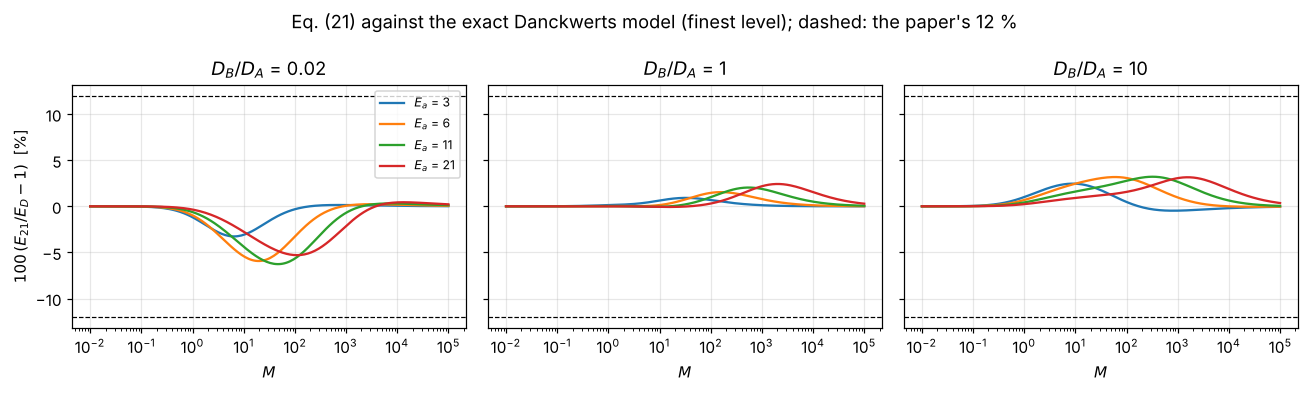

In [8]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
Ms_plot = np.geomspace(*M_WIN, 200)
for ax, rs in zip(axs, R_GRID):
    for ea in EA_GRID:
        h = levels(C0, ea, rs)[-1]
        ax.semilogx(Ms_plot, [err21(h, ea, C0)[0](x) for x in Ms_plot], label=f"$E_a$ = {ea:g}")
    ax.axhline(num(PN, "danckwerts_bound_pct"), color="k", ls="--", lw=0.8)
    ax.axhline(-num(PN, "danckwerts_bound_pct"), color="k", ls="--", lw=0.8)
    ax.set_title(f"$D_B/D_A$ = {rs}")
    ax.set_xlabel("$M$")
axs[0].set_ylabel("$100\\,(E_{21}/E_D - 1)$  [%]")
axs[0].legend(fontsize=8)
fig.suptitle("Eq. (21) against the exact Danckwerts model (finest level); dashed: the paper's 12 %")
fig.tight_layout()
plt.show()

### R2. Equal diffusivities, and the film comparison of `F3.1`

At $D_B = D_A$ the bridging relation (15) is exact for the Danckwerts model: the
linear combination behind it needs no approximation there. The exact solve confirms it
at the test condition, so at $r = 1$ all of the error of Eq. (21) is the step from (15)
to (19), B frozen at its mean. At $E_a = 100$ the error can be set beside `F3.1`'s film
result at the same $E_i$.

In [9]:
say("At $E_a$ = 6, $D_B/D_A$ = 1, $M$ = 24 the Danckwerts mean of $b(0)$ and "
    "$(E_a - E_D)/(E_a - 1)$ differ by <<g:.1e>> on the finest level, falling at order "
    "<<o:.3f>> to <<x:.1e>> extrapolated. At $E_a$ = 100 the worst error of Eq. (21) against "
    "the Danckwerts model is <<w:.3f>> % at $M$ = <<m:.4g>>; `F3.1` finds <<f:.3f>> % against the "
    "film model at $M = \\mathrm{Ha}^2$ = <<mf:.4g>>, where the Danckwerts error is <<a:.3f>> %. "
    "At `F3.1`'s own worst point Eq. (21) is thus <<a:.2e>> % from the Danckwerts model "
    "though <<f:.3f>> % above the film model: `F3.1`'s figure is the difference between the "
    "film and surface-renewal models. (The ratio of the two worsts, <<s:.3f>>, is at different $M$.)",
    g=M["r2_idgap_finest"], o=M["r2_idgap_order"], x=M["r2_idgap_ext"], w=M["r2_ea100_worst_pct"],
    m=M["r2_ea100_worst_M"], f=F31["decoursey_worst_error_pct"], mf=F31["decoursey_worst_ha"] ** 2,
    a=M["r2_at_f31_M_pct"], s=M["r2_share_of_f31"])

At $E_a$ = 6, $D_B/D_A$ = 1, $M$ = 24 the Danckwerts mean of $b(0)$ and $(E_a - E_D)/(E_a - 1)$ differ by 5.0e-06 on the finest level, falling at order 2.030 to 7.6e-08 extrapolated. At $E_a$ = 100 the worst error of Eq. (21) against the Danckwerts model is 2.855 % at $M$ = 4.724e+04; `F3.1` finds 8.730 % against the film model at $M = \mathrm{Ha}^2$ = 2.036, where the Danckwerts error is -0.001 %. At `F3.1`'s own worst point Eq. (21) is thus -1.16e-03 % from the Danckwerts model though 8.730 % above the film model: `F3.1`'s figure is the difference between the film and surface-renewal models. (The ratio of the two worsts, 0.327, is at different $M$.)

### R3. Where the error comes from

The paper attributes the approximation "chiefly" to treating $B_i/B_0$ as constant in
time. Removing one ingredient at a time: Eq. (19) fed the **exact** mean $\bar b_i$ of
the solve (so only the constant-in-time step remains) against Eq. (21) (which also uses
the bridging relation for $\bar b_i$).

In [10]:
print(f"{'E_a':>4} {'Eq.(19), exact mean b_i':>24} {'Eq.(21)':>9}   (largest error % on the window, D_B/D_A = 1)")
for ea in EA_GRID:
    k = key(ea, "1")
    print(f"{ea:4.0f} {M[f'r3_e19_worst_pct_{k}']:24.3f} {M[f'r1_worst_pct_{k}']:9.3f}")
say("At equal diffusivities the constant-in-time step alone overestimates $E$ by up to "
    "<<a:.2f>> % (largest over the four $E_a$; in <<i:d>> of 4 cases the largest value sits at the "
    "window end, $M = 10^5$, so the error is still rising there), while Eq. (21) "
    "is within <<b:.3f>> %: the self-consistent mean of (15) under-predicts $\\bar b_i$ and "
    "compensates most of it. This is a measured gap on this grid of cases, not a general "
    "result. At $D_B/D_A$ = 0.02 the bridging relation itself fails: at $E_a$ = 6, $M$ = 24 the "
    "exact mean of $b(0)$ is <<c:.4f>> against <<d:.4f>> from (15) with the exact $E_D$.",
    a=M["r3_e19_max_pct"], i=M["r3_n_e19_at_end"], b=M["r3_e21_max_r1_pct"],
    c=M["r3_meanb0_6_0.02"], d=M["r3_bridge_6_0.02"])

 E_a  Eq.(19), exact mean b_i   Eq.(21)   (largest error % on the window, D_B/D_A = 1)
   3                   10.199     0.914
   6                   18.241     1.538
  11                   25.154     2.035
  21                   29.988     2.421


At equal diffusivities the constant-in-time step alone overestimates $E$ by up to 29.99 % (largest over the four $E_a$; in 4 of 4 cases the largest value sits at the window end, $M = 10^5$, so the error is still rising there), while Eq. (21) is within 2.421 %: the self-consistent mean of (15) under-predicts $\bar b_i$ and compensates most of it. This is a measured gap on this grid of cases, not a general result. At $D_B/D_A$ = 0.02 the bridging relation itself fails: at $E_a$ = 6, $M$ = 24 the exact mean of $b(0)$ is 0.5162 against 0.4428 from (15) with the exact $E_D$.

### R4. Table 1 recomputed with the exact Higbie average

The correction is $100\,(E_H/E_{21} - 1)$ at the printed $M$, with $E_H$ the Higbie
average of the same march ($\theta_e = 4M/\pi$). A printed integer agrees "within
print" when the recomputed value rounds to it (half a unit), and within the charts'
stated accuracy when the gap is at most 3 % of $E_H$ (in points, $3(1 + c/100)$) plus
half a unit.

In [11]:
print(f"{'M':>6} {'printed %':>10} {'recomputed %':>13} {'gap':>7}")
for i, (x, p) in enumerate(zip(T1_M, T1_P), 1):
    print(f"{x:6g} {p:10g} {M[f'r4_corr_{i}']:13.3f} {abs(p - M[f'r4_corr_{i}']):7.3f}")
say("<<a:d>> of 7 printed corrections round from the recomputed value; all <<b:d>> of 7 are within "
    "the charts' 3 % plus half a unit. The largest gap is <<g:.3f>> points, at $M$ = <<m:g>> "
    "(printed <<p>>, recomputed <<r:.3f>>).",
    a=M["r4_n_round"], b=M["r4_n_allow"], g=M["r4_max_gap"], m=M["r4_max_gap_M"],
    p=printed(PN, "t1_corr_4"), r=M["r4_corr_4"])

     M  printed %  recomputed %     gap
  0.83         -2        -1.855   0.145
  1.84         -2        -1.191   0.809
   8.7          3         2.336   0.664
    24          6         4.311   1.689
    67          5         4.753   0.247
   302          2         2.520   0.520
   660          2         1.433   0.567


2 of 7 printed corrections round from the recomputed value; all 7 of 7 are within the charts' 3 % plus half a unit. The largest gap is 1.689 points, at $M$ = 24 (printed 6, recomputed 4.311).

### R5. Table 2 recomputed

For each case, the exact smallest and largest Higbie correction over Table 1's span of
$M$ (M3), each root-found or at a window end, against the printed range. A printed range
from a finite set of $M$ can only be narrower than the exact one, so a printed maximum
above the exact maximum by more than the chart allowance is a decidable disagreement; a
printed maximum below it is not.

In [12]:
print(f"{'E_a':>4} {'D_B/D_A':>8} {'printed':>12} {'exact min':>10} {'exact max':>10}")
for ea, rs in CASES:
    k = key(ea, rs)
    pr = f"{printed(PN, f't2_{int(ea)}_{rs}_lo')} to {printed(PN, f't2_{int(ea)}_{rs}_hi')}"
    print(f"{ea:4.0f} {rs:>8} {pr:>12} {M[f'r5_hmin_{k}']:10.3f} {M[f'r5_hmax_{k}']:10.3f}")
say("<<a:d>> of 24 printed range ends are within the charts' allowance of the exact extremes "
    "(largest gap <<w:.3f>> allowances); <<b:d>> of 12 printed maxima lie above the exact maximum "
    "by more than the allowance. The paper's derived statement, corrections \"no more than "
    "<<p6>> per cent at equal diffusivities and no more than <<p14>> per cent\" at $D_B/D_A$ = 0.02 "
    "(p. 1870), holds for the exact Higbie model: <<e:.3f>> % and <<f:.3f>> %.",
    a=M["r5_n_inside"], w=M["r5_worst_gap_ratio"], b=M["r5_n_max_above"],
    p6=printed(PN, "max_corr_equal_pct"), p14=printed(PN, "max_corr_002_pct"),
    e=M["r5_max_equal_pct"], f=M["r5_max_002_pct"])

 E_a  D_B/D_A      printed  exact min  exact max
   3     0.02     -2 to +8     -0.380      9.236
   3        1     -2 to +5     -1.148      4.458
   3       10     -2 to +3     -1.715      3.041
   6     0.02    -2 to +13     -1.338     12.907
   6        1     -2 to +6     -1.855      4.842
   6       10     -3 to +3     -2.285      2.704
  11     0.02    -1 to +14     -1.820     12.839
  11        1     -2 to +5     -2.144      4.655
  11       10     -3 to +3     -2.459      2.960
  21     0.02    -2 to +12     -2.107     10.930
  21        1     -2 to +4     -2.327      4.383
  21       10     -2 to +2     -2.519      3.301


24 of 24 printed range ends are within the charts' allowance of the exact extremes (largest gap 0.464 allowances); 0 of 12 printed maxima lie above the exact maximum by more than the allowance. The paper's derived statement, corrections "no more than 6 per cent at equal diffusivities and no more than 14 per cent" at $D_B/D_A$ = 0.02 (p. 1870), holds for the exact Higbie model: 4.842 % and 12.907 %.

### R6. The paper's 3 per cent premise

The prediction rests on the statement that Higbie and Danckwerts pseudo-first-order
enhancement factors "agree within 3 per cent at all values of the parameter M from zero
to infinity" (p. 1870). Both are closed forms, $\sqrt{1 + M}$ and Eq. (23) with $f = 1$.

In [13]:
say("The largest difference, $100\\,(E_H/E_D - 1)$, is <<w:.4f>> % at $M$ = <<m:.5f>> (root of "
    "the analytic derivative; interior: <<i>>): the premise holds (<<h>>). "
    "Against the exact second-order model, Eq. (21) stays within <<r:.3f>> %, so the paper's "
    "12 per cent, built by adding its Higbie corrections to that premise, was loose by a factor "
    "of <<f:.3f>>.",
    w=M["r6_pfo_worst_pct"], m=M["r6_pfo_worst_M"], i=M["_r6_interior"], h=M["r6_premise_holds"],
    r=M["r1_worst_abs_pct"], f=M["r1_margin"])

The largest difference, $100\,(E_H/E_D - 1)$, is -2.5494 % at $M$ = 1.26592 (root of the analytic derivative; interior: True): the premise holds (True). Against the exact second-order model, Eq. (21) stays within 6.271 %, so the paper's 12 per cent, built by adding its Higbie corrections to that premise, was loose by a factor of 1.914.

## Validation

- **V1, limits.** B frozen ($q \to \infty$) must give $\sqrt{1 + M}$ for Danckwerts and
  the erf form of Eq. (23) with $f = 1$ for Higbie at every $M$; Eq. (21) at
  $E_a = 10^{12}$ is that same $\sqrt{1 + M}$, so it must meet the frozen solve (the
  approximation exact by construction). Slow reaction: $(E - 1)/(M/2) \to 1$. Fast
  reaction: $E_a - E_D$ falls as a power of $M$, measured.
- **V2, check values**: above, before the first result.
- **V3, cells** at a fine step and **V4, steps** at a fine grid, each a three-level
  ladder at the test case and at the R1 worst case. Companions: the cell ladder with B
  frozen, against the exact $\sqrt{1 + M}$; and the finest difference against the
  change from a hundredfold tighter Newton tolerance.
- **V5**: the domain end raised by half, the start age over a decade either side, and
  the quadrature refined (Gauss points and subintervals both doubled).

In [14]:
say("V1: with B frozen the extrapolated Danckwerts and Higbie averages meet $\\sqrt{1 + M}$ and "
    "Eq. (23) with $f = 1$ to <<a:.1e>> and <<b:.1e>> (largest relative gap over $M$ from 0.01 to "
    "660; finest level alone <<c:.1e>>); Eq. (21) at $E_a = 10^{12}$ meets the frozen solve to "
    "<<d:.1e>>. Slow limit at $M$ = 0.01: $(E_D - 1)/(M/2)$ = <<s:.5f>>, within <<t:.1e>> of the "
    "pseudo-first-order value. Fast limit: $d\\ln(E_a - E_D)/d\\ln M$ from $10^4$ to $10^5$ is "
    "<<f:.4f>>, so $E_a - E_D$ falls as $1/M$, as for Eq. (21).",
    a=M["v1_frozen_D_gap"], b=M["v1_frozen_H_gap"], c=M["v1_frozen_D_gap_finest"],
    d=M["v1_e21_limit_gap"], s=M["v1_slow_ratio"], t=M["v1_slow_vs_pfo"], f=M["v1_fast_slope"])
say("V3, cells (100 to 400, step 0.01): observed order <<a1:.3f>> at the test case (error "
    "estimate <<a2:.1e>>) and <<b1:.3f>> at the worst case (<<b2:.1e>> points); with B frozen, "
    "against the exact value, <<c1:.3f>> (finest error <<c3:.1e>>). V4, steps (0.04 to 0.01, "
    "400 cells): <<d1:.3f>> (<<d2:.1e>>) and <<e1:.3f>> (<<e2:.1e>> points). The finest cell difference is "
    "<<r:.2e>> times the Newton tolerance effect (<<t:.1e>>). V5: domain <<v1:.1e>>, start age "
    "<<v2:.1e>>, quadrature <<v3:.1e>> (relative changes of $E_D$ at the test case).",
    a1=M["v3_test_order"], a2=M["v3_test_errest"], b1=M["v3_worst_order"],
    b2=M["v3_worst_errest"], c1=M["v3_frozen_order"], c3=M["v3_frozen_finest_err"],
    d1=M["v4_test_order"], d2=M["v4_test_errest"], e1=M["v4_worst_order"], e2=M["v4_worst_errest"],
    r=M["v3_finest_over_tol"],
    t=M["v3_tol_effect"], v1=M["v5_domain_change"], v2=M["v5_theta0_change"], v3=M["v5_quad_change"])

V1: with B frozen the extrapolated Danckwerts and Higbie averages meet $\sqrt{1 + M}$ and Eq. (23) with $f = 1$ to 1.0e-05 and 6.1e-06 (largest relative gap over $M$ from 0.01 to 660; finest level alone 8.3e-05); Eq. (21) at $E_a = 10^{12}$ meets the frozen solve to 1.0e-05. Slow limit at $M$ = 0.01: $(E_D - 1)/(M/2)$ = 0.99641, within 1.1e-03 of the pseudo-first-order value. Fast limit: $d\ln(E_a - E_D)/d\ln M$ from $10^4$ to $10^5$ is -0.9916, so $E_a - E_D$ falls as $1/M$, as for Eq. (21).

V3, cells (100 to 400, step 0.01): observed order 1.996 at the test case (error estimate 4.4e-05) and 1.997 at the worst case (1.6e-03 points); with B frozen, against the exact value, 2.000 (finest error 9.4e-05). V4, steps (0.04 to 0.01, 400 cells): 1.960 (1.0e-06) and 1.921 (2.3e-05 points). The finest cell difference is 6.06e+09 times the Newton tolerance effect (2.2e-14). V5: domain 2.8e-06, start age 3.3e-11, quadrature 0.0e+00 (relative changes of $E_D$ at the test case).

### The claims

In [15]:
RTOL = 1e-6
STRUCTURAL = {"c_e20_residual": "Eq. (21) is the positive root of Eq. (20) squared",
              "c_e22_test": "Eq. (22) at the test condition, a scalar root of the printed relation (asserted as a check value)",
              "r6_pfo_worst_pct": "two closed forms, sqrt(1 + M) and Eq. (23) with f = 1",
              "r6_pfo_worst_M": "two closed forms, sqrt(1 + M) and Eq. (23) with f = 1"}
BOUNDS = {"c_e20_residual": (None, 1e-14, "identity", STRUCTURAL["c_e20_residual"]),
          "r1_max_errest": (None, 0.01, "chosen", "Richardson error estimate of the 12 worst errors, in points; the margin to 12 % is near 6 points"),
          "r1_order_min": (1.8, 2.5, "theory", "second order in cells and steps; pre-asymptotic up to about 2.4"),
          "r1_order_max": (1.8, 2.5, "theory", "second order in cells and steps; pre-asymptotic up to about 2.4"),
          "r2_idgap_finest": (None, 2e-5, "theory", "exact identity at r = 1, discretisation O(h^2) on 400 cells"),
          "r2_idgap_ext": (None, 1e-6, "theory", "exact identity at r = 1, after Richardson extrapolation"),
          "r2_idgap_order": (1.8, 2.2, "theory", "second order"),
          "v1_frozen_D_gap": (None, 3e-5, "chosen", "extrapolated discretisation remainder, M from 0.01 to 660"),
          "v1_frozen_H_gap": (None, 3e-5, "chosen", "extrapolated discretisation remainder, M from 0.01 to 660"),
          "v1_frozen_D_gap_finest": (None, 2e-4, "theory", "O(h^2) on the finest level"),
          "v1_e21_limit_gap": (None, 3e-5, "chosen", "Eq. (21) at E_a = 1e12 is sqrt(1 + M); extrapolated remainder"),
          "v1_slow_vs_pfo": (None, 5e-3, "chosen", "slow limit: depletion of B of order M"),
          "v1_fast_slope": (-1.05, -0.95, "chosen", "measured local slope of ln(E_a - E_D) between M 1e4 and 1e5"),
          "v3_test_order": (1.9, 2.1, "theory", "second-order finite volumes"),
          "v3_worst_order": (1.9, 2.1, "theory", "second-order finite volumes"),
          "v3_frozen_order": (1.9, 2.1, "theory", "second-order finite volumes, against the exact value"),
          "v4_test_order": (1.8, 2.2, "theory", "BDF2"),
          "v4_worst_order": (1.8, 2.2, "theory", "BDF2"),
          "v3_test_errest": (None, 1e-4, "chosen", "cell error of E_D on 400 cells"),
          "v3_worst_errest": (None, 5e-3, "chosen", "cell error of the worst error on 400 cells, in points"),
          "v4_test_errest": (None, 1e-5, "chosen", "step error of E_D at step 0.01"),
          "v4_worst_errest": (None, 5e-4, "chosen", "step error of the worst error at step 0.01, in points"),
          "v3_frozen_finest_err": (None, 2e-4, "theory", "O(h^2) on 400 cells"),
          "v3_tol_effect": (None, 1e-10, "tolerance", "newton tol 1e-10 against 1e-12"),
          "v3_finest_over_tol": (1e3, None, "chosen", "the finest cell difference at least 1e3 times the solver effect"),
          "v5_domain_change": (None, 1e-5, "chosen", "eta_max 6 against 9"),
          "v5_theta0_change": (None, 1e-9, "chosen", "start age 1e-8 to 1e-6"),
          "v5_quad_change": (None, 1e-12, "tolerance", "Gauss points and subintervals doubled")}
MARGINS = {"r1_n_within": 0.05, "r4_n_round": 0.01, "r4_n_allow": 0.05, "r5_n_inside": 0.05,
           "r5_n_max_above": 0.05, "r5_paper6_holds": 0.05, "r5_paper14_holds": 0.05,
           "r6_premise_holds": 0.05}
EXACT = {"r1_n_interior", "r1_worst_case", "r3_n_e19_at_end"}


def register(M):
    """Register every reported number with its kind."""
    for name, v in M.items():
        if name.startswith("_") or name.endswith("__margin"):
            continue
        if name in BOUNDS:
            lo, hi, basis, note = BOUNDS[name]
            claims.bound(name, v, min=lo, max=hi, basis=basis, structural=name in STRUCTURAL, note=note)
        elif name in MARGINS:
            claims.exact(name, v, margin=M[name + "__margin"], min_margin=MARGINS[name])
        elif name in EXACT:
            claims.exact(name, v)
        elif name in STRUCTURAL:
            claims.value(name, v, rtol=RTOL, note="structural: " + STRUCTURAL[name])
            claims.metrics[name]["structural"] = True
        else:
            claims.value(name, v, rtol=RTOL)


register(M)
claims.value("f31_decoursey_worst_error_pct_loaded", F31["decoursey_worst_error_pct"], rtol=RTOL,
             note="F3.1's committed claim, loaded, the denominator of r2_share_of_f31")
claims.metrics["f31_decoursey_worst_error_pct_loaded"]["structural"] = True

### The break table

Every non-structural number registered above has a row that moves it. Each row injects
one defect through `Cfg` (a reading of the paper, a printed entry, the model, the
discretisation or a solver setting) and reruns the parts of the study the defect
reaches, on the cases listed; marches that the defect does not touch come from the
cache. Only finite values are recorded; a row under which the study raises is listed.
The control fails nothing. Structural, with no row: Eq. (21) as the root of (20), the
value of Eq. (22) at the test condition (a check value), the two closed forms of R6, and
`F3.1`'s loaded number.

In [16]:
def printed_row(item, new, parts, cases=CASES):
    """A break row that mistypes one printed entry."""
    pn = PN.copy()
    i = pn.index[pn["item"] == item][0]
    old = pn.at[i, "printed"]
    pn.at[i, "printed"] = new
    return f"printed {item} {old} -> {new}", replace(C0, pn=pn), parts, cases


UNEQUAL = [(6.0, "0.02"), (11.0, "0.02"), (6.0, "10")]
POST = ("sweep", "big", "test", "frozen", "grid", "steps")
DEFECTS = [
    ("Eq. (23) as printed, erfc (M1)", replace(C0, ha_fn="erfc"), ("closed",), []),
    ("Eq. (14) q = E_a - 1 at unequal diffusivities (M2)", replace(C0, q_rule="eq14"), ("sweep",), UNEQUAL),
    ("Higbie exposure theta_e = M, not 4M/pi", replace(C0, exposure="M"), ("sweep", "test", "frozen"), CASES),
    ("b = 1 at the interface, not b_eta = 0", replace(C0, b_wall="dirichlet"), ("sweep", "test"),
     [(6.0, "1"), (6.0, "0.02"), (11.0, "0.02")]),
    ("Danckwerts weight e^-theta (the 1/M dropped)", replace(C0, weight="unit"), POST + ("v5",), CASES),
    ("D_B/D_A = 0.98 in the equal-diffusivity case", replace(C0, r_test=0.98), ("test",), []),
    ("eta_max = 2 in the domain test", replace(C0, eta_max=2.0), ("v5",), []),
    ("(E_a - 1)^1 under M^2/4 in Eq. (21)", replace(C0, q_power=1), ("closed", "big", "test", "frozen", "grid", "steps"), []),
    ("upwind face value of the eta/2 flux", replace(C0, conv="upwind"), ("grid", "sweep", "test"), [(11.0, "0.02")]),
    ("backward Euler steps in sigma", replace(C0, scheme="euler"), ("steps",), []),
    ("tolerance companion run with q 1e-6 high", replace(C0, comp_q=1 + 1e-6), ("companion",), []),
    ("start ages 1e-4 to 1e-2", replace(C0, theta0_ladder=(1e-4, 1e-3, 1e-2)), ("v5",), []),
    ("one Gauss point per step", replace(C0, n_gauss=1), ("v5",), []),
    ("M window cut at 10", replace(C0, m_hi=10.0), ("sweep",), CASES),
    printed_row("t1_corr_4", "4", ("test",), []),
    printed_row("t2_6_0.02_hi", "+17", ("sweep",)),
    printed_row("danckwerts_bound_pct", "5", ("sweep",)),
    printed_row("pfo_agreement_pct", "2", ("closed",), []),
    printed_row("brian_chart_accuracy_pct", "1", ("sweep", "test")),
    printed_row("max_corr_equal_pct", "4", ("sweep",)),
    printed_row("max_corr_002_pct", "12", ("sweep",)),
]
CONTROLS = [("control: clean rerun of the closed forms and the test case", C0, ("closed", "test"), [])]
claims.define_rows([r_ for r_, _, _, _ in CONTROLS + DEFECTS])
BREAK, CRASH = [], {}
for row, c_, parts, cases in CONTROLS + DEFECTS:
    Mb = {}
    for part in parts:                # one part at a time, so a crash costs only its own claims
        try:
            with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
                Mb.update(study(c_, (part,), cases))
        except (ValueError, RuntimeError, ZeroDivisionError, FloatingPointError) as e:
            CRASH[f"{row} [{part}]"] = f"{type(e).__name__}: {e}"
    for name in claims.metrics:
        if claims.metrics[name].get("structural"):
            continue
        x_ = Mb.get(name, None)
        if x_ is None or (isinstance(x_, (float, np.floating)) and not np.isfinite(x_)):
            continue                  # only finite values are recorded
        BREAK.append((row, name, claims.breaks(row, name, x_)))

In [17]:
# The break table: one line per row, with the claims it fails.
by_row = {}
for r_, m_, c_ in BREAK:
    by_row.setdefault(r_, []).append(c_)
_bad = [r_ for r_ in by_row if r_.startswith("control") and any(by_row[r_])]
assert not _bad, f"a control row failed a claim: {_bad}"
print(f"{'injected defect':<58} {'recorded':>8} {'failed':>7}")
for r_, cs in by_row.items():
    print(f"{r_[:58]:<58} {len(cs):8d} {sum(cs):7d}")
for r_, e_ in CRASH.items():
    print(f"crashed part: {r_}: {e_}")
_caught = {m_ for r_, m_, c_ in BREAK if c_}
_open = sorted(k_ for k_ in claims.metrics if k_ not in _caught
               and not claims.metrics[k_].get("structural"))
_n_struct = sum(1 for k_ in claims.metrics if claims.metrics[k_].get("structural"))
print(f"\n{len(by_row)} rows; {len(_caught)} of {len(claims.metrics)} claims are failed by at "
      f"least one row; structural: {_n_struct}; open: {', '.join(_open) or 'none'}")

injected defect                                            recorded  failed
control: clean rerun of the closed forms and the test case       24       0
Eq. (23) as printed, erfc (M1)                                    3       1
Eq. (14) q = E_a - 1 at unequal diffusivities (M2)               16      14
Higbie exposure theta_e = M, not 4M/pi                           99      42
b = 1 at the interface, not b_eta = 0                            38      36
Danckwerts weight e^-theta (the 1/M dropped)                    116      56
D_B/D_A = 0.98 in the equal-diffusivity case                     21      16
eta_max = 2 in the domain test                                    3       1
(E_a - 1)^1 under M^2/4 in Eq. (21)                              42      18
upwind face value of the eta/2 flux                              33      29
backward Euler steps in sigma                                     4       4
tolerance companion run with q 1e-6 high                          8       2
start ages 1

## What pymrm adds

The exact surface-renewal model the paper could not test against. pymrm solves the
coupled transient A/B equations in similarity variables: `construct_grad`,
`construct_div` and `construct_coefficient_matrix` for the per-field diffusion, the two
`construct_convflux_upwind` operators averaged into a central flux for the similarity
term, all assembled once on a graded grid; per-field boundary conditions with the
interface flux and $b(0)$ read by `compute_boundary_values` under the same conditions;
and one `pymrm.newton` solve per BDF2 step, with `NumJac((n, 2))` for the pointwise
reaction. `pymrm.checks.find_roots` gives every extremum as the single root of its
derivative between scan neighbours, and the instantaneous asymptote's $q$;
`pymrm.checks.observed_orders` gives the orders and every extrapolated value. Not
pymrm: Eqs. (20) to (23) and the pseudo-first-order forms are closed forms (scipy for
erf), and the age averages are a spline quadrature.

## Reuse

- `model.RenewalMarch(q, r).run()` returns a `History` with `danckwerts(M)`,
  `higbie(M)` and `mean_b0(M)` at every $M$ up to the march's end over 30; it is the
  Danckwerts and Higbie solver `F3.4` needs. `q_from_ea(E_a, r)` maps the paper's
  $E_a$ to $q$ at any diffusivity ratio.
- Eq. (21) is a good explicit estimate for the Danckwerts model over the paper's grid
  (the worst error above); it is not a film-model estimate (`F3.1`) and not a Higbie
  estimate (Tables 1 and 2). Outside $E_a$ 3 to 21 and $D_B/D_A$ 0.02 to 10 (and the
  $E_a$ = 100, $D_B/D_A$ = 1 case) this page says nothing.
- For a reversible reaction, $A_0 \ne 0$ or another order, change the source in
  `RenewalMarch._source` and the boundary values; the averages do not change.
- Related pages: `F3.1` (regimes and the film comparison), `F3.2` (Van
  Krevelen-Hoftijzer against the film), `F3.4` (Danckwerts theory), `F3.5`
  (CO2-amine absorption).

In [18]:
# Claims: prints every registered number, writes agreement.json for CI, and
# raises when a claim fails its own check or has no break row.
claims.report();   # the semicolon keeps the notebook from echoing the payload

Claims for F3.3:
  c_e21_test                           = 3.5632           value  rtol 1e-06
  c_e22_test                           = 3.4827           value  rtol 1e-06
  c_e23_test                           = 3.5463           value  rtol 1e-06
  c_e20_residual                       = (here 1.3e-15)   bound  bound <= 1e-14 [identity]
  r6_pfo_worst_pct                     = -2.5494          value  rtol 1e-06
  r6_pfo_worst_M                       = 1.2659           value  rtol 1e-06
  r6_premise_holds                     = True             exact  exact, margin 0.15
  r1_worst_pct_3_0.02                  = -3.2653          value  rtol 1e-06
  r1_worst_M_3_0.02                    = 6.4733           value  rtol 1e-06
  r5_hmin_3_0.02                       = -0.38006         value  rtol 1e-06
  r5_hmax_3_0.02                       = 9.2357           value  rtol 1e-06
  r1_worst_pct_3_1                     = 0.91362          value  rtol 1e-06
  r1_worst_M_3_1                       = 32.484 